##Basic Optimization

In this page we shall demosntrate how to use Scipy's optimization package.


Lets optimize $f(x) = \exp{(x-2)^2}$

In [ ]:
# !pip install scikit-optimize
import importlib.util
if importlib.util.find_spec('skopt') is None:
    import sys, subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'scikit-optimize', '-q'])


In [2]:
import numpy as np
import matplotlib.pyplot as mp
import scipy as sp
from scipy import optimize
from scipy import fftpack
import skopt as opt

def f(y):
    return -np.exp(-(y-2)**2)

result = optimize.minimize_scalar(f)

print(result)

 message: 
          Optimization terminated successfully;
          The returned value satisfies the termination criteria
          (using xtol = 1.48e-08 )
 success: True
     fun: -1.0
       x: 1.9999999955459995
     nit: 6
    nfev: 10



###Using minimize function
We can also use Python's minimize or maximize function (with the ''key'' option) to optimize the function!

You can also pass more arguments.

Why to use the "optimize" function then?

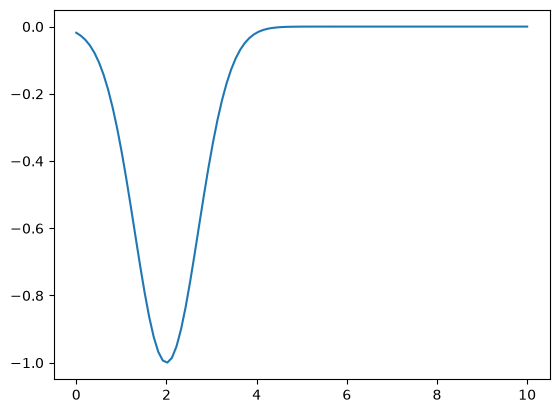

2.0202020202020203


In [3]:
y = np.linspace(0,10,100)
mp.plot(y,-np.exp(-(y-2)**2)); mp.show()
#print(max(y, key=lambda x: np.sinc(x-5)))

print(min(y, key=lambda x: -np.exp(-(x-2)**2)))

###Rosenbrock function

Now we optimize the infamous Rosenbrock function.

$f(x,y) = 0.5*(1-x)^2 + (y - x^2)^2$

In [4]:
def f(x):   # The rosenbrock function
    return .5*(1 - x[0])**2 + (x[1] - x[0]**2)**2
optimize.minimize(f, [0,-1], method="CG")

 message: Optimization terminated successfully.
 success: True
  status: 0
     fun: 1.2743806081839638e-11
       x: [ 1.000e+00  1.000e+00]
     nit: 8
     jac: [-2.100e-07  2.518e-06]
    nfev: 48
    njev: 16

What happens if we change the seed to something very far from the solution point?

In [5]:
optimize.minimize(f, [200,-110], method="CG")

 message: Optimization terminated successfully.
 success: True
  status: 0
     fun: 2.9893539643535623e-10
       x: [ 1.000e+00  1.000e+00]
     nit: 19
     jac: [ 6.787e-06  8.506e-06]
    nfev: 158
    njev: 52

**Constrained Optimization**

In this you need to give the constraints as well.

For example: $f(x) = 2xy + 2x - x^2 - 2 y^2$.

Constraints are as follows:

$x^3−y = 0$

$y−1 \geq 0$

In [6]:
def func(x, sign=1.0):
    """ Objective function """
    return sign*(2*x[0]*x[1] + 2*x[0] - x[0]**2 - 2*x[1]**2)

cons = ({'type': 'eq',
          'fun' : lambda x: np.array([x[0]**3 - x[1]])},
        {'type': 'ineq',
          'fun' : lambda x: np.array([x[1] - 1])})

res = optimize.minimize(func, [-1.0,1.0], args=(-1.0,),
                method='SLSQP', options={'disp': True})
print(res.x)

Optimization terminated successfully    (Exit mode 0)
            Current function value: -2.000000000000001
            Iterations: 4
            Function evaluations: 13
            Gradient evaluations: 4
[2.00000002 1.00000001]


In [7]:
res = optimize.minimize(func, [-1.0,1.0], args=(-1.0,),
                constraints=cons, method='BFGS', options={'disp': True})

print(res.x)

Optimization terminated successfully.
         Current function value: -2.000000
         Iterations: 6
         Function evaluations: 21
         Gradient evaluations: 7
[2.00000024 1.00000014]


/var/folders/zj/lzpt73xj0l5bd2yk4zcdzr7m0000gn/T/ipykernel_36239/2128810766.py:1: RuntimeWarning: Method BFGS cannot handle constraints.
  res = optimize.minimize(func, [-1.0,1.0], args=(-1.0,),


## COMPRESSIVE SENSING

Now lets discuss about compressive sensing. Lets assume that we have some signal recorded (following Nyquist rate); lets call it $x$. Its size is $N$.

In the following signal we are using 500 samples and two sinusoids. You can note that one of them takes 10 samples per cycle; hence there are 50 cycles. So Nyquist will want us to have at least 100 samples in order to be able to know whats in the signal!

However if we look the signal through DCT then there are just two samples. Mark that we are using DCT and not FFT; because then we dont have to deal with complex numbers!



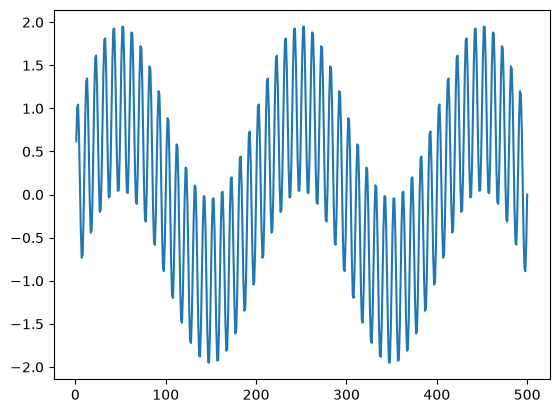

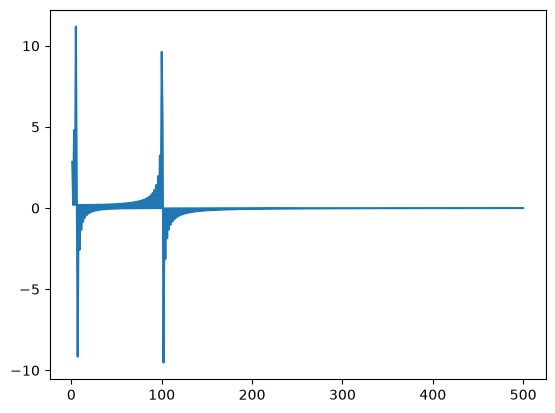

([<matplotlib.lines.Line2D at 0x11ae217f0>], None)

In [8]:
n = np.linspace(1,500,500)

#two harmonics signal
xx = np.sin(2*np.pi*n/10) + np.sin(2*np.pi*n/200)  #+ np.sin(2*np.pi*n/50)
mp.plot(n,xx), mp.show()
mp.plot(n,fftpack.dct(xx, norm='ortho')), mp.show()

**Sparse Sampling** \\
Lets assume that we only consider $n$ of this ($n \ll N$).

For this lets define a sparsifying vector sp which has only $n$ 1's and rest zeros placed in random places.

So sparsed data $xp = xx*sp$.

The trick is that these $n$ samples are randomly taken.

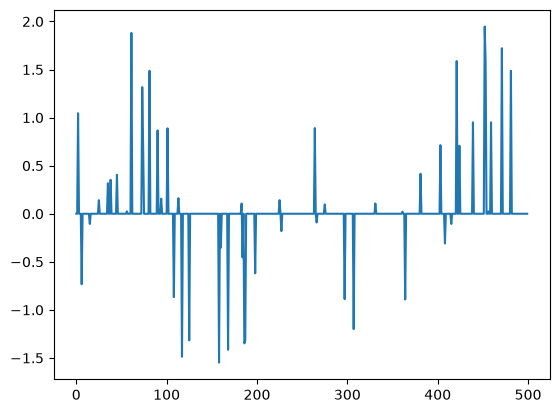

([<matplotlib.lines.Line2D at 0x11b08c590>], None)

In [9]:
N = len(xx) #length of actual N
n = 50 #number of nonzero samples in our sparse signal
sp = np.array([1] * n + [0] * (N-n)) #n 1's and (N-n) 0's
np.random.shuffle(sp)

xp = xx*sp
mp.plot(xp), mp.show()

### Using Optimization
The trick of compressive sensing is that we try to use optimization in order to know the unknown from what is known!

So let us think what we know.

1- We know $xp$  the random-subNyquist-sampled signal and $sp$.

2- We know that the signal is sparse in DCT domain.

So lets try to look into the DCT domain. Lets assume that the DCT of the signal is $XX$. So IDCT of it should give us $xp$ back.

Lets define an optimization problem to do this.

What are the DCT samples that will give rise to a time domain signal which has the values of $xp$ at $sp$ time-indices. \\
We start with an intial estimate $XX$ which we will update in each iteration. \\
The cost function will be Euclidean distance between $xp$ and IDCT of $XX$.

         Current function value: 0.000000
         Iterations: 10
         Function evaluations: 67647
         Gradient evaluations: 135


/Users/krzysiek/Desktop/ML4Space/.venv/lib/python3.15/site-packages/scipy/optimize/_minimize.py:779: OptimizeWarning: Desired error not necessarily achieved due to precision loss.
  res = _minimize_bfgs(fun, x0, args, jac, callback, **options)


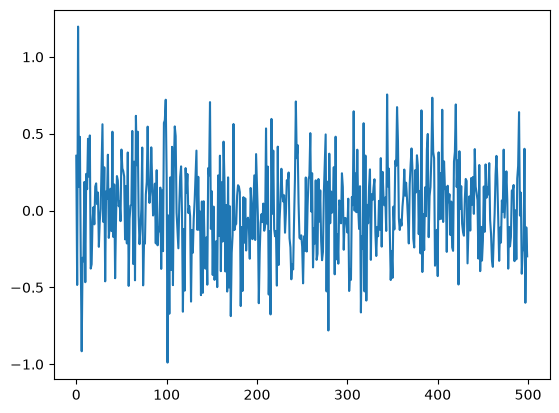

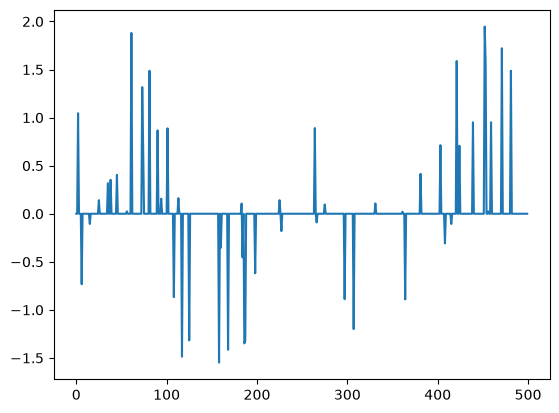

([<matplotlib.lines.Line2D at 0x11b159be0>], None)

In [10]:

XX = np.random.rand(N)
def cost_cs(XX):   #given the measured xp and a generic X find the L1 norm
    xd = fftpack.idct(XX, norm='ortho') #derived x from X
    xdn = xd*sp
    return np.linalg.norm((xdn - xp), ord=2)

seed = np.zeros(N)

CS = optimize.minimize(cost_cs, seed, options={'disp': True})

xrecon = fftpack.idct(CS.x, norm='ortho')
mp.plot(CS.x), mp.show()
mp.plot(xrecon), mp.show()

### Redfining the Optimization
Hmmmm. Enen though the optimization has not finished doing its job if we look at the result we seem to have achieved what we asked for!

The reconstructed signal $xrecon$ looks exactly like $xp$. So we did achieve what we wanted (theoritically speaking) but we want more.

What else can we do?

Lets add a condition that we want to optimize $||xrecon - xp ||$ but we also want to keep XX sparse, i.e. the $L0$ norm of $XX$ should be less than $n$.

Iteration limit reached    (Exit mode 9)
            Current function value: 3.0637191259200634e-05
            Iterations: 100
            Function evaluations: 51283
            Gradient evaluations: 101


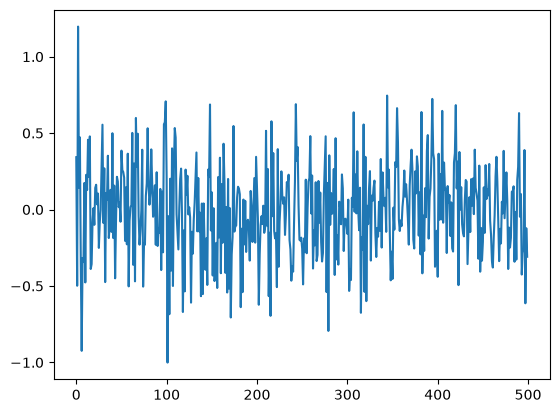

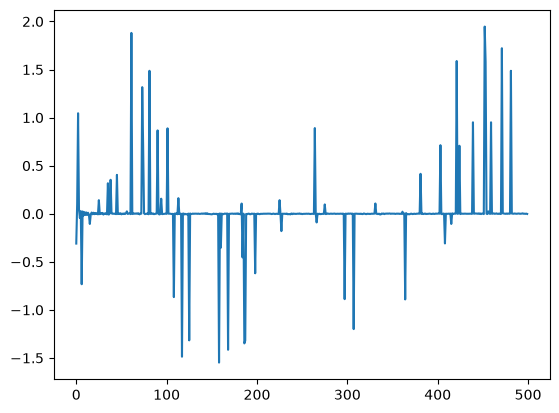

([<matplotlib.lines.Line2D at 0x11b213230>], None)

In [11]:
XX = np.random.rand(N)
def cost_cs(XX):   #given the measured xp and a generic X find the L1 norm
    xd = fftpack.idct(XX, norm='ortho') #derived x from X
    xdn = xd*sp
    return np.linalg.norm((xdn - xp), ord=2)

cons = ({'type': 'ineq',
          'fun' : lambda XX: n - np.linalg.norm(XX,ord=0)})

#seed = np.random.rand(N)
seed = np.zeros(N)

CS = optimize.minimize(cost_cs, seed, constraints=cons, options={'disp': True})

xrecon = fftpack.idct(CS.x, norm='ortho')
mp.plot(CS.x), mp.show()
mp.plot(xrecon), mp.show()

### Re-redfining the Optimization: L1 Magic!!
Hmmmm. It seems its not working the way we want it to work. What else can we do?

It seems achieving $xrecon = xp$ is an easy task, because its sparse anyway.

So lets keep this as a condition (instead of making it the cost-function). And minimize $XX$. And let us use $L1$ norm here so as to keep the error under control. Remember that even though $L2$ norm is smooth, it has a square and blows up the error. So in wildly uknown problems like what we dealing with here, its better to use $L1$ norm.

In [12]:
XX = np.random.rand(N)
def cost_cs(XX):   #given the measured xp and a generic X find the L1 norm
    return np.linalg.norm(XX, ord=1)

cons = ({'type': 'eq',
          'fun' : lambda XX : np.linalg.norm(xp - fftpack.idct(XX, norm='ortho')*sp, ord = 2)})

seed = np.random.rand(N)
#seed = np.zeros(N)

CS = optimize.minimize(cost_cs, seed, constraints=cons, options={'disp': True})

Iteration limit reached    (Exit mode 9)
            Current function value: 59.47692394453989
            Iterations: 100
            Function evaluations: 50933
            Gradient evaluations: 101


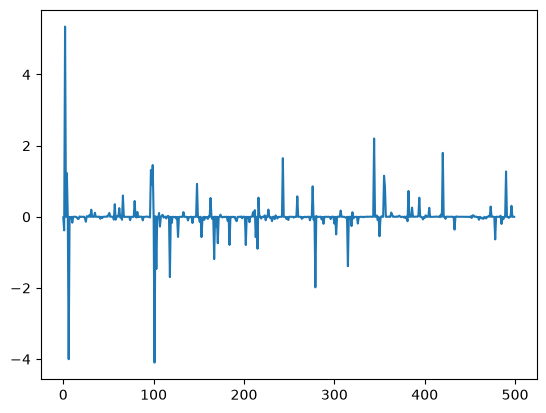

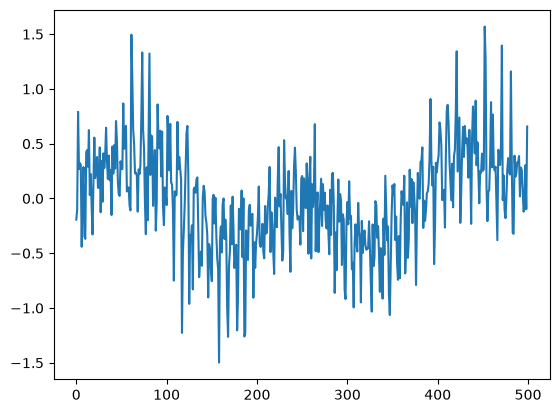

([<matplotlib.lines.Line2D at 0x11b2106e0>], None)

In [13]:
xrecon = fftpack.idct(CS.x, norm='ortho')
mp.plot(CS.x), mp.show()
mp.plot(xrecon), mp.show()

### Conclusion
Unfortunately the optimization process did not end. We need more iteration. However, we seem to have got something which looks pretty much like the signal we have started with. It is noisy but it is encouraging given the fact that we have got only half the number of samples as Nyquist would have wanted.

This is the starting of Compressive Sensing (CS). We have learnt two things.

1- It is easy to cheat Nyquist if the signal is sparse in some other linearly transferable domain. 2- Redefining the optimization problem can help us achieve magical results.

The hard-core CS involvs more interesting objective functions and constraints to achieve even more interesting magical results.

#===== STUDENT WORK (ex2 assignment) =====

## 1) Probability Distribution Function (PDF) of Sentinel data

Same regions as in ex1:
- **Natural:** Białowieża forest (Poland)
- **Urban:** Warsaw (Poland)

Data stored next to this notebook in `satellite_data/`:
- Sentinel-2 L2A bands **B02, B03, B04**
- Sentinel-1 RTC polarizations **VV, VH**



In [14]:
#=====
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

DATA = Path("satellite_data")

s2_natural = np.load(DATA / "s2_natural_forest_pl.npz")
s2_urban = np.load(DATA / "s2_urban_warsaw_pl.npz")
s1_natural = np.load(DATA / "s1_natural_forest_pl.npz")
s1_urban = np.load(DATA / "s1_urban_warsaw_pl.npz")

print("S2 natural item:", s2_natural["item_id"])
print("S2 urban item:  ", s2_urban["item_id"])
print("S1 natural item:", s1_natural["item_id"])
print("S1 urban item:  ", s1_urban["item_id"])
print("S2 bands:", [k for k in s2_natural.files if k != "item_id"])
print("S1 bands:", [k for k in s1_natural.files if k != "item_id"])
#=====


S2 natural item: S2A_MSIL2A_20230928T093031_R136_T34UFD_20230928T154238
S2 urban item:   S2A_MSIL2A_20230815T095031_R079_T34UDC_20241014T195621
S1 natural item: S1A_IW_GRDH_1SDV_20230930T043627_20230930T043652_050552_0616C8_rtc
S1 urban item:   S1A_IW_GRDH_1SDV_20230928T045252_20230928T045317_050523_0615C1_rtc
S2 bands: ['B02', 'B03', 'B04']
S1 bands: ['VV', 'VH']


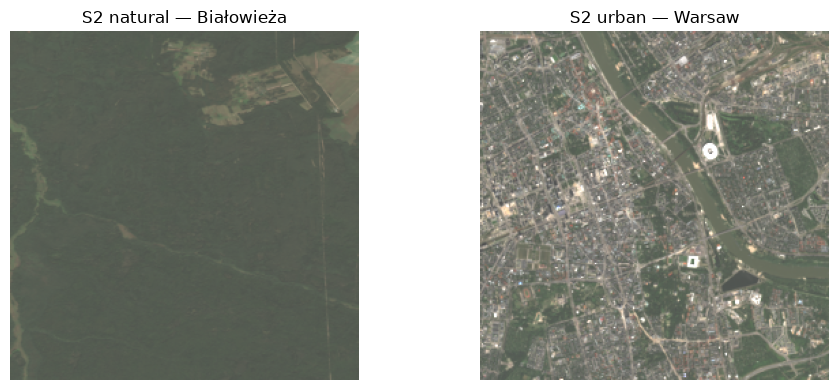

In [15]:
#=====
# Preview Sentinel-2 true-color (B04,B03,B02) for both AOIs
def s2_rgb(npz, vmax=3500):
    rgb = np.dstack([npz["B04"], npz["B03"], npz["B02"]]).astype(float)
    return np.clip(rgb / vmax, 0, 1)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(s2_rgb(s2_natural)); axes[0].set_title("S2 natural — Białowieża"); axes[0].axis("off")
axes[1].imshow(s2_rgb(s2_urban)); axes[1].set_title("S2 urban — Warsaw"); axes[1].axis("off")
plt.tight_layout(); plt.show()
#=====


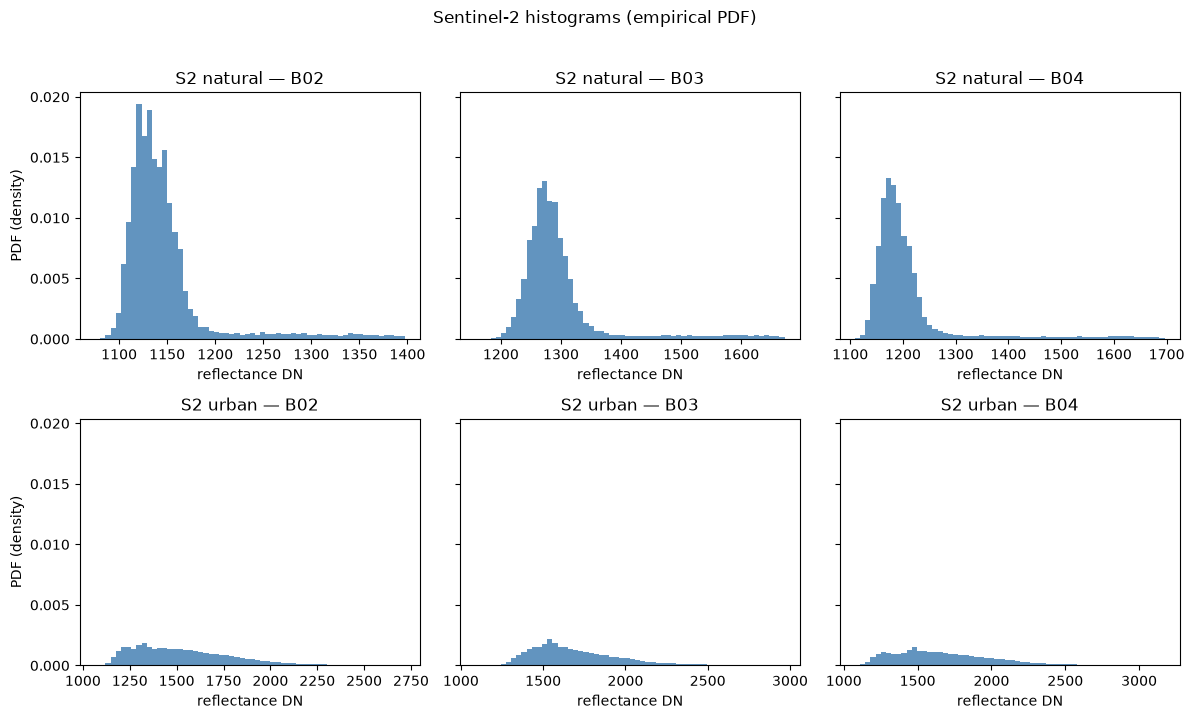

In [16]:
#=====
# Histograms / PDF for Sentinel-2 (3 bands × 2 terrains)
s2_bands = ["B02", "B03", "B04"]
fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharey=True)

for col, band in enumerate(s2_bands):
    for row, (label, npz) in enumerate([("natural", s2_natural), ("urban", s2_urban)]):
        vals = npz[band].ravel()
        # drop zeros/nodata-ish and clip extreme reflectance for readable PDF
        vals = vals[vals > 0]
        hi = np.percentile(vals, 99)
        vals = vals[vals <= hi]
        axes[row, col].hist(vals, bins=60, density=True, alpha=0.85, color="steelblue")
        axes[row, col].set_title(f"S2 {label} — {band}")
        axes[row, col].set_xlabel("reflectance DN")
        if col == 0:
            axes[row, col].set_ylabel("PDF (density)")

plt.suptitle("Sentinel-2 histograms (empirical PDF)", y=1.02)
plt.tight_layout(); plt.show()
#=====


### Observations — Sentinel-2 histograms

- **Natural (forest):** reflectance is concentrated at **lower values**, especially in B02/B04; vegetation absorbs much red/blue and reflects more in green (B03), so B03 often sits a bit higher / broader than B02–B04.
- **Urban (Warsaw):** histograms are **wider and shifted toward brighter values** — roofs, concrete and bare surfaces raise reflectance in all three visible bands.
- PDF shape is therefore a simple terrain fingerprint: forest → darker, peaked; city → brighter, heavier right tail.



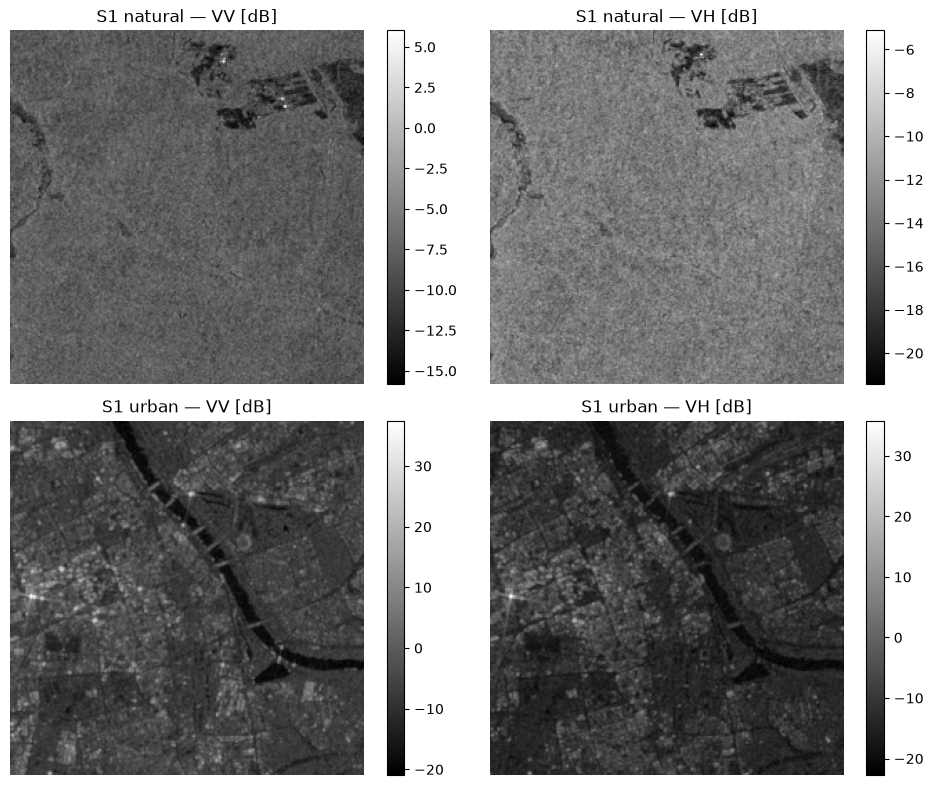

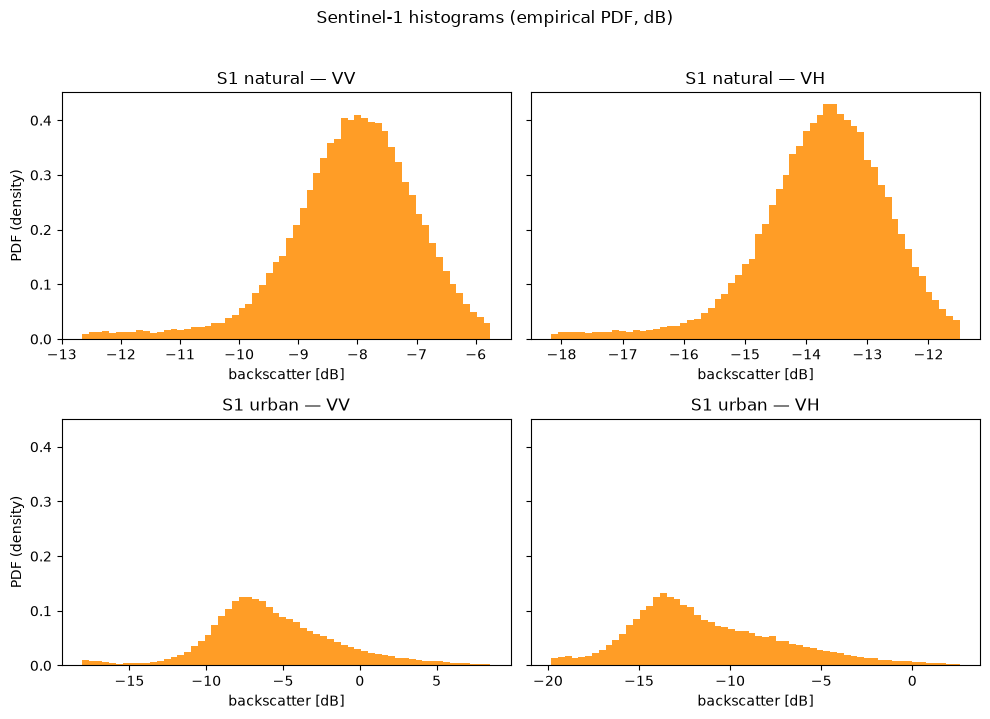

In [17]:
#=====
# Sentinel-1 preview (log scale helps with dynamic range) + histograms
def s1_db(arr):
    return 10 * np.log10(np.maximum(arr, 1e-6))

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for row, (label, npz) in enumerate([("natural", s1_natural), ("urban", s1_urban)]):
    for col, pol in enumerate(["VV", "VH"]):
        img = s1_db(npz[pol])
        im = axes[row, col].imshow(img, cmap="gray")
        axes[row, col].set_title(f"S1 {label} — {pol} [dB]")
        axes[row, col].axis("off")
        plt.colorbar(im, ax=axes[row, col], fraction=0.046)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharey=True)
for row, (label, npz) in enumerate([("natural", s1_natural), ("urban", s1_urban)]):
    for col, pol in enumerate(["VV", "VH"]):
        vals = s1_db(npz[pol]).ravel()
        lo, hi = np.percentile(vals, [1, 99])
        vals = vals[(vals >= lo) & (vals <= hi)]
        axes[row, col].hist(vals, bins=60, density=True, alpha=0.85, color="darkorange")
        axes[row, col].set_title(f"S1 {label} — {pol}")
        axes[row, col].set_xlabel("backscatter [dB]")
        if col == 0:
            axes[row, col].set_ylabel("PDF (density)")
plt.suptitle("Sentinel-1 histograms (empirical PDF, dB)", y=1.02)
plt.tight_layout(); plt.show()
#=====


### Observations — Sentinel-1 histograms (same regions)

- **Forest:** VV/VH backscatter is relatively **moderate and more concentrated** — volume scattering from canopy, less extreme bright returns.
- **Urban:** PDF is **broader with a bright tail** (especially VV) — double-bounce from buildings creates strong returns; VH also rises vs forest.
- Compared to S2 optical PDFs: S1 is weather/illumination independent and highlights **structure** (city vs vegetation) rather than color/reflectance.



## 2) Steganography — replace last 2 LSBs

Take a Sentinel-2 band (urban B04). Replace the **2 least significant bits** of each pixel with a **random** 2-bit value (independent per pixel).

Questions:
1. Does visual quality change?
2. Do the histograms / PDFs differ?
3. Can this detect manipulated satellite images?



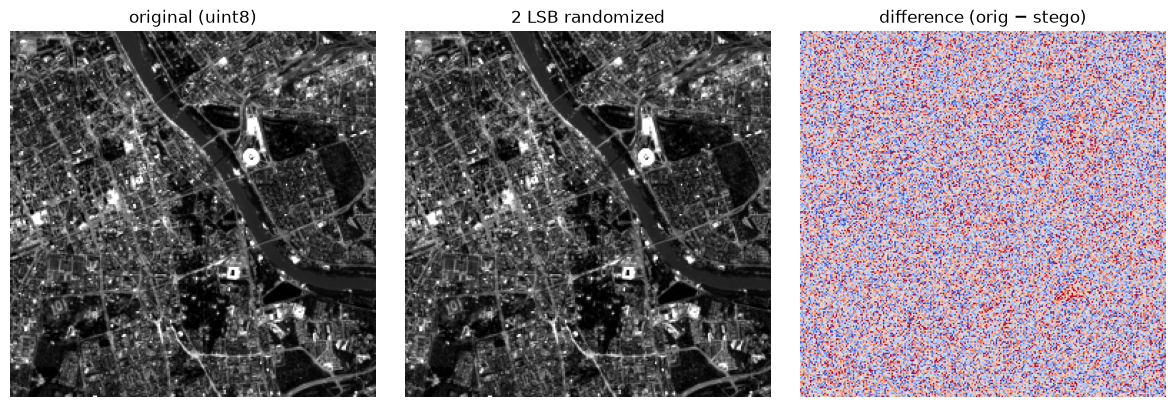

MSE = 2.521, PSNR = 44.11 dB
Max abs pixel change: 3


In [18]:
#=====
# Work on uint8 display version of urban B04 (typical 8-bit image pipeline)
band = s2_urban["B04"].astype(float)
# scale to 0..255 for LSB experiment
bmin, bmax = np.percentile(band, [1, 99])
img8 = np.clip((band - bmin) / (bmax - bmin + 1e-9) * 255, 0, 255).astype(np.uint8)

rng = np.random.default_rng(42)
rand2 = rng.integers(0, 4, size=img8.shape, dtype=np.uint8)  # values 0..3 = 2 bits

# clear last 2 bits, then insert random bits
img_stego = (img8 & np.uint8(0b11111100)) | rand2

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(img8, cmap="gray"); axes[0].set_title("original (uint8)"); axes[0].axis("off")
axes[1].imshow(img_stego, cmap="gray"); axes[1].set_title("2 LSB randomized"); axes[1].axis("off")
axes[2].imshow(img_stego.astype(int) - img8.astype(int), cmap="coolwarm", vmin=-3, vmax=3)
axes[2].set_title("difference (orig − stego)"); axes[2].axis("off")
plt.tight_layout(); plt.show()

mse = np.mean((img8.astype(float) - img_stego.astype(float)) ** 2)
psnr = 10 * np.log10((255 ** 2) / (mse + 1e-12))
print(f"MSE = {mse:.3f}, PSNR = {psnr:.2f} dB")
print("Max abs pixel change:", int(np.max(np.abs(img_stego.astype(int) - img8.astype(int)))))
#=====


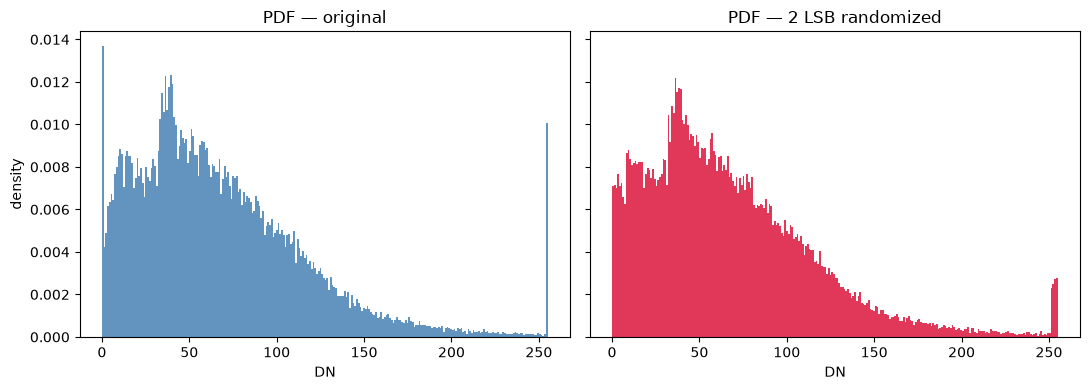

P(last 2 bits) original : [0.2581 0.2466 0.2433 0.252 ]
P(last 2 bits) stego    : [0.254  0.2502 0.2484 0.2474]


In [19]:
#=====
# PDF / histogram: original vs LSB-manipulated
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
axes[0].hist(img8.ravel(), bins=256, range=(0, 255), density=True, color="steelblue", alpha=0.85)
axes[0].set_title("PDF — original")
axes[0].set_xlabel("DN"); axes[0].set_ylabel("density")

axes[1].hist(img_stego.ravel(), bins=256, range=(0, 255), density=True, color="crimson", alpha=0.85)
axes[1].set_title("PDF — 2 LSB randomized")
axes[1].set_xlabel("DN")
plt.tight_layout(); plt.show()

# zoom on fine structure: count of even/odd patterns in last 2 bits
def lsb2_hist(a):
    return np.bincount(a.ravel() & 0b11, minlength=4) / a.size

print("P(last 2 bits) original :", np.round(lsb2_hist(img8), 4))
print("P(last 2 bits) stego    :", np.round(lsb2_hist(img_stego), 4))
#=====


### Observations — steganography / LSB

1. **Visual quality:** almost unchanged. Changing 2 LSBs alters a pixel by at most ±3 DN on 0–255, so the image still looks the same to the eye (high PSNR).
2. **PDF / histogram:** the coarse shape of the histogram stays similar, but the **fine bin-to-bin structure** changes. After randomization, the last-2-bit pattern becomes nearly uniform (`00,01,10,11 ≈ 25%` each). Natural images usually have a slightly uneven LSB pattern.
3. **Detection?** Yes, as a *weak forensic cue*: if LSBs look perfectly uniform / uncorrelated while MSBs look natural, the file may have been LSB-stego’d or otherwise bit-level manipulated. It is **not** a perfect detector (compression, resampling, or sensor noise can also disturb LSBs), but comparing original vs suspect PDFs / LSB statistics is a classic first check.



## 3) (Optional) Compressive sensing — run + EO notes

Instructor CS cells above show the idea (DCT sparsity → undersample → optimize).
`scipy.optimize.minimize` often stalls on the hard equality constraint, so below is a **small, working ISTA** version of the same idea, then notes on EO usefulness.



samples used: 100/500
MSE=0.1661, corr=0.926, approx non-zero DCT peaks=30


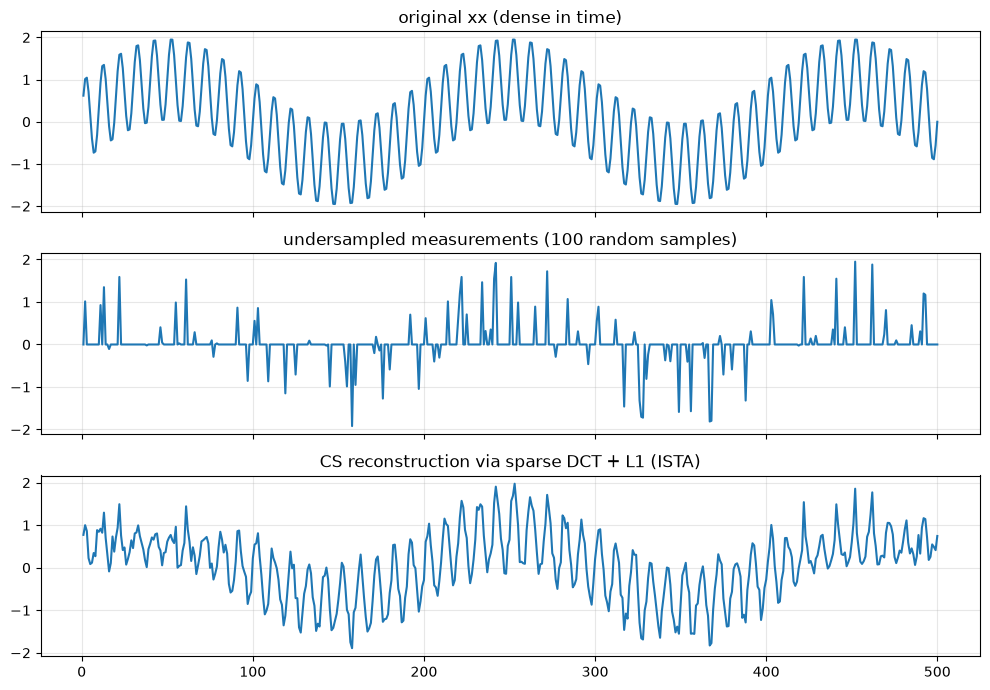

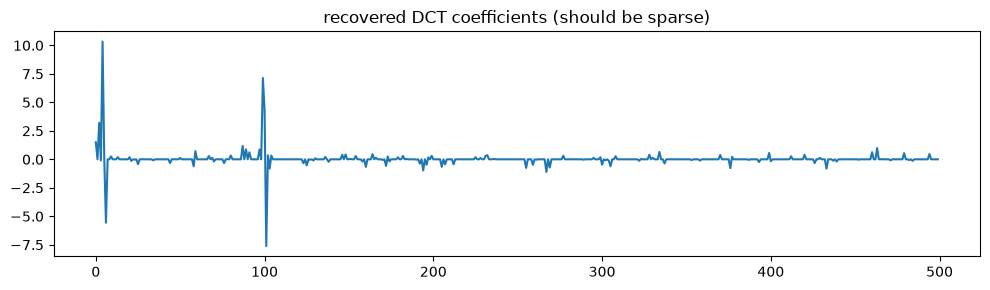

In [20]:
#=====
# Practical CS demo (ISTA): recover 2-sine signal from random undersampling
from scipy import fftpack

np.random.seed(0)
t = np.linspace(1, 500, 500)
xx = np.sin(2 * np.pi * t / 10) + np.sin(2 * np.pi * t / 200)
N = len(xx)

n_samp = 100  # Nyquist-ish lower bound in the text was ~100 for the fast sine
mask = np.zeros(N)
mask[np.random.choice(N, n_samp, replace=False)] = 1.0
y = mask * xx  # known samples only; elsewhere 0 in this zero-filled view

# ISTA on DCT coeffs X:  minimize  0.5 ||mask * idct(X) - y||^2  +  lam * ||X||_1
lam, step, n_iter = 0.02, 0.5, 500
X = fftpack.dct(y, norm="ortho")
for _ in range(n_iter):
    x = fftpack.idct(X, norm="ortho")
    grad = fftpack.dct(mask * x - y, norm="ortho")
    Z = X - step * grad
    X = np.sign(Z) * np.maximum(np.abs(Z) - lam * step, 0.0)

xrecon = fftpack.idct(X, norm="ortho")
mse = float(np.mean((xrecon - xx) ** 2))
corr = float(np.corrcoef(xrecon, xx)[0, 1])
nnz = int(np.sum(np.abs(X) > 0.05 * np.max(np.abs(X))))

print(f"samples used: {n_samp}/{N}")
print(f"MSE={mse:.4f}, corr={corr:.3f}, approx non-zero DCT peaks={nnz}")

fig, axes = mp.subplots(3, 1, figsize=(10, 7), sharex=True)
axes[0].plot(t, xx); axes[0].set_title("original xx (dense in time)")
axes[1].plot(t, y); axes[1].set_title(f"undersampled measurements ({n_samp} random samples)")
axes[2].plot(t, xrecon); axes[2].set_title("CS reconstruction via sparse DCT + L1 (ISTA)")
for ax in axes:
    ax.grid(True, alpha=0.3)
mp.tight_layout(); mp.show()

mp.figure(figsize=(10, 3))
mp.plot(X)
mp.title("recovered DCT coefficients (should be sparse)")
mp.tight_layout(); mp.show()
#=====


### Observations — optional CS

**What this gives:** from only ~100 random time samples we reconstruct a signal that needs ~500 points to store naively, because in DCT it is sparse (~few large peaks). That is the whole point of the optional task: CS is useful when a transform makes the data sparse.

**Where useful in EO**
- **Downlink / onboard compression:** limited satellite bandwidth → send fewer measurements / coefficients if the scene is sparse in DCT/wavelets, reconstruct on ground.
- **Incomplete acquisitions:** SAR, gaps, missing scans — recover under a sparsity prior instead of simple interpolation.
- **Sparse sampling campaigns:** fewer revisits / spatial samples when the geophysical field is smooth/sparse in a known basis.

**Caveat for real satellite images:** forest/urban textures are only *approximately* sparse; noise and calibration mean CS is a useful prior, not magic like this 2-sine toy.

#===== END STUDENT WORK =====

